Experiment 6: CRP Scaling Analysis


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pathlib import Path

from pypuf.simulation import XORArbiterPUF

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Project folders
PROJECT_DIR = Path.home() / "University" / "System_Software_Security"

RESULTS_DIR = PROJECT_DIR / "04_Results"
GRAPHS_DIR = PROJECT_DIR / "05_Graphs"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

# Experiment parameters
N = 64
NUM_CRPS = 20000

XOR_COUNTS = [1, 2, 3, 4]
PUF_SEEDS = [101, 202, 303]

TRAINING_SIZES = [
    500, 1000, 2500, 5000, 10000, 16000
]

TEST_SIZE = 4000

print("CRP scaling experiment configured!")
print("Challenge length:", N)
print("XOR counts:", XOR_COUNTS)
print("PUF seeds:", PUF_SEEDS)
print("Training sizes:", TRAINING_SIZES)
print("Fixed testing samples:", TEST_SIZE)

CRP scaling experiment configured!
Challenge length: 64
XOR counts: [1, 2, 3, 4]
PUF seeds: [101, 202, 303]
Training sizes: [500, 1000, 2500, 5000, 10000, 16000]
Fixed testing samples: 4000


In [2]:
# Generate 20,000 common challenges
rng = np.random.default_rng(42)

challenges = rng.choice(
    [-1, 1],
    size=(NUM_CRPS, N)
)

# Apply Arbiter PUF feature transformation
X_transformed = np.flip(
    np.cumprod(
        np.flip(challenges, axis=1),
        axis=1
    ),
    axis=1
)

# First 16,000 are the training pool
# Last 4,000 are reserved for testing

TRAIN_POOL = np.arange(16000)
TEST_INDICES = np.arange(16000, 20000)

X_train_pool = X_transformed[TRAIN_POOL]
X_test = X_transformed[TEST_INDICES]

print("Training pool:", X_train_pool.shape)
print("Testing dataset:", X_test.shape)
print("Feature transformation completed!")

Training pool: (16000, 64)
Testing dataset: (4000, 64)
Feature transformation completed!


In [3]:
crp_results = []

for seed in PUF_SEEDS:

    print("\n" + "=" * 60)
    print(f"PUF SEED: {seed}")
    print("=" * 60)

    for k in XOR_COUNTS:

        print(f"\nTesting {k}-XOR PUF")

        # Create PUF
        puf = XORArbiterPUF(
            n=N,
            k=k,
            seed=seed,
            noisiness=0
        )

        # Generate responses
        responses = np.asarray(
            puf.eval(challenges)
        ).reshape(-1)

        y = np.where(responses == 1, 1, 0)

        # Separate training and testing responses
        y_train_pool = y[TRAIN_POOL]
        y_test = y[TEST_INDICES]

        # Check response distribution
        print(
            "Testing response distribution:",
            np.bincount(y_test, minlength=2)
        )

        # Generate one reproducible nested ordering
        subset_rng = np.random.default_rng(seed + k * 1000)
        train_order = subset_rng.permutation(len(TRAIN_POOL))

        for num_crps in TRAINING_SIZES:

            selected = train_order[:num_crps]

            X_train = X_train_pool[selected]
            y_train = y_train_pool[selected]

            print(f"\nTraining with {num_crps} CRPs")

            models = [
                (
                    "LR Transformed",
                    LogisticRegression(
                        max_iter=3000,
                        random_state=42
                    )
                ),
                (
                    "MLP Transformed",
                    make_pipeline(
                        StandardScaler(),
                        MLPClassifier(
                            hidden_layer_sizes=(128, 64),
                            activation="relu",
                            solver="adam",
                            max_iter=200,
                            early_stopping=True,
                            n_iter_no_change=15,
                            random_state=42
                        )
                    )
                )
            ]

            for model_name, model in models:

                start = time.perf_counter()

                model.fit(X_train, y_train)

                elapsed = time.perf_counter() - start

                predictions = model.predict(X_test)

                accuracy = accuracy_score(
                    y_test,
                    predictions
                ) * 100

                crp_results.append({
                    "PUF_Seed": seed,
                    "XOR_Count": k,
                    "Training_CRPs": num_crps,
                    "Model": model_name,
                    "Accuracy": accuracy,
                    "Training_Time": elapsed
                })

                print(
                    f"{model_name}: {accuracy:.2f}% "
                    f"| Time: {elapsed:.3f}s"
                )

print("\nALL CRP SCALING EXPERIMENTS COMPLETED!")


PUF SEED: 101

Testing 1-XOR PUF
Testing response distribution: [1967 2033]

Training with 500 CRPs
LR Transformed: 94.33% | Time: 0.015s
MLP Transformed: 88.08% | Time: 0.050s

Training with 1000 CRPs
LR Transformed: 97.12% | Time: 0.001s
MLP Transformed: 90.25% | Time: 0.052s

Training with 2500 CRPs
LR Transformed: 98.55% | Time: 0.001s
MLP Transformed: 94.45% | Time: 0.152s

Training with 5000 CRPs
LR Transformed: 99.02% | Time: 0.002s
MLP Transformed: 96.08% | Time: 0.235s

Training with 10000 CRPs
LR Transformed: 99.40% | Time: 0.004s
MLP Transformed: 96.67% | Time: 0.426s

Training with 16000 CRPs
LR Transformed: 99.55% | Time: 0.005s
MLP Transformed: 97.38% | Time: 1.522s

Testing 2-XOR PUF
Testing response distribution: [2030 1970]

Training with 500 CRPs
LR Transformed: 49.30% | Time: 0.001s
MLP Transformed: 50.45% | Time: 0.019s

Training with 1000 CRPs
LR Transformed: 49.73% | Time: 0.001s
MLP Transformed: 51.68% | Time: 0.052s

Training with 2500 CRPs
LR Transformed: 50.3

In [4]:
crp_results_df = pd.DataFrame(crp_results)

crp_results_df.to_csv(
    RESULTS_DIR / "crp_scaling_individual_results.csv",
    index=False
)

display(crp_results_df.head(15))

print("Individual CRP scaling results saved!")
print("Total experiment runs:", len(crp_results_df))

,PUF_Seed,XOR_Count,Training_CRPs,Model,Accuracy,Training_Time
0,101,1,500,LR Transformed,94.325,0.014729
1,101,1,500,MLP Transformed,88.075,0.050099
2,101,1,1000,LR Transformed,97.125,0.001074
3,101,1,1000,MLP Transformed,90.250,0.052030
4,101,1,2500,LR Transformed,98.550,0.001447
5,101,1,2500,MLP Transformed,94.450,0.151839
6,101,1,5000,LR Transformed,99.025,0.002205
7,101,1,5000,MLP Transformed,96.075,0.234826
8,101,1,10000,LR Transformed,99.400,0.003823
9,101,1,10000,MLP Transformed,96.675,0.425991


Individual CRP scaling results saved!
Total experiment runs: 144


In [5]:
crp_summary = (
    crp_results_df
    .groupby([
        "XOR_Count",
        "Training_CRPs",
        "Model"
    ])["Accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

crp_summary = crp_summary.rename(columns={
    "mean": "Mean_Accuracy",
    "std": "Std_Accuracy"
})

crp_summary = crp_summary.round(2)

display(crp_summary)

crp_summary.to_csv(
    RESULTS_DIR / "crp_scaling_summary.csv",
    index=False
)

print("Summary results saved!")

,XOR_Count,Training_CRPs,Model,Mean_Accuracy,Std_Accuracy
0,1,500,LR Transformed,93.81,1.05
1,1,500,MLP Transformed,87.31,1.59
2,1,1000,LR Transformed,96.58,0.58
3,1,1000,MLP Transformed,90.98,0.65
4,1,2500,LR Transformed,98.42,0.19
5,1,2500,MLP Transformed,94.59,0.62
6,1,5000,LR Transformed,98.92,0.15
7,1,5000,MLP Transformed,96.15,0.15
8,1,10000,LR Transformed,99.31,0.12
9,1,10000,MLP Transformed,96.91,0.23


Summary results saved!


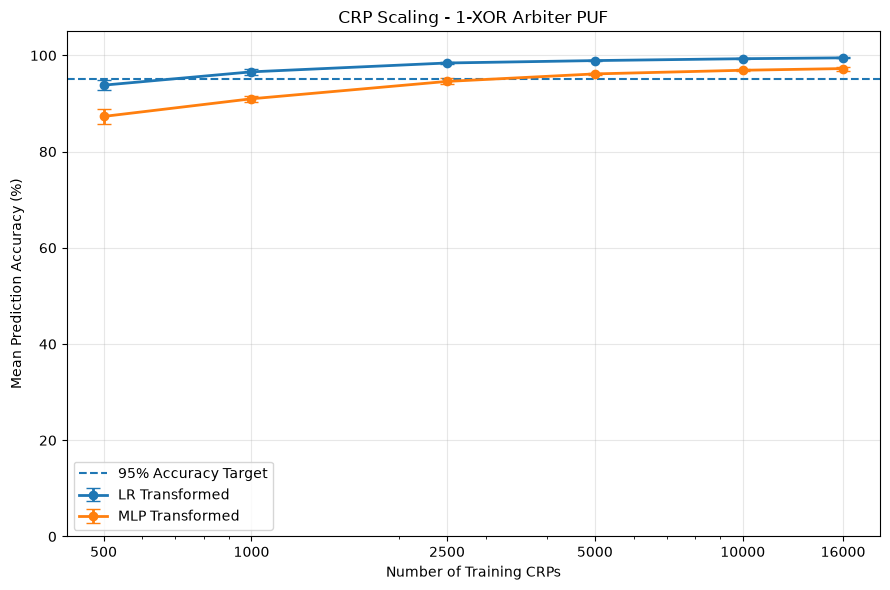

Saved: crp_scaling_1xor.png


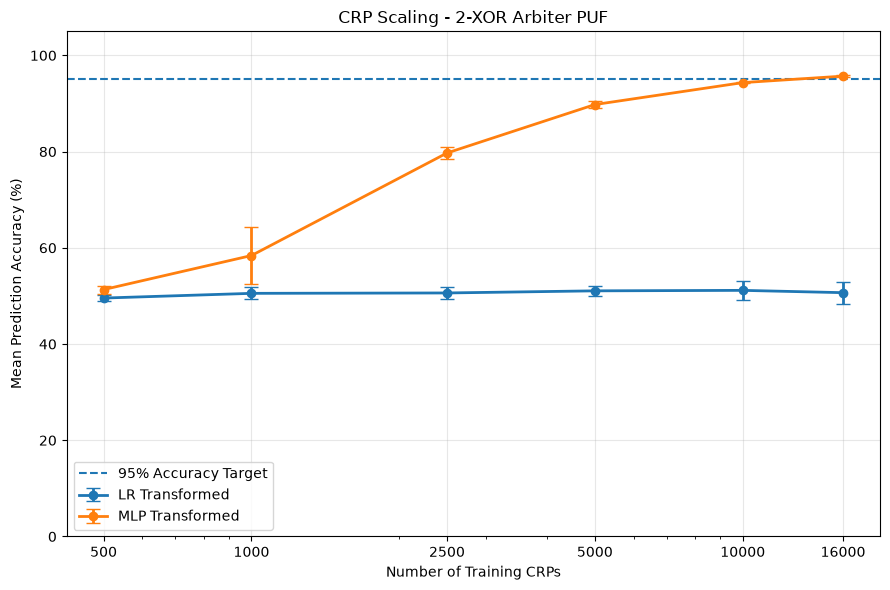

Saved: crp_scaling_2xor.png


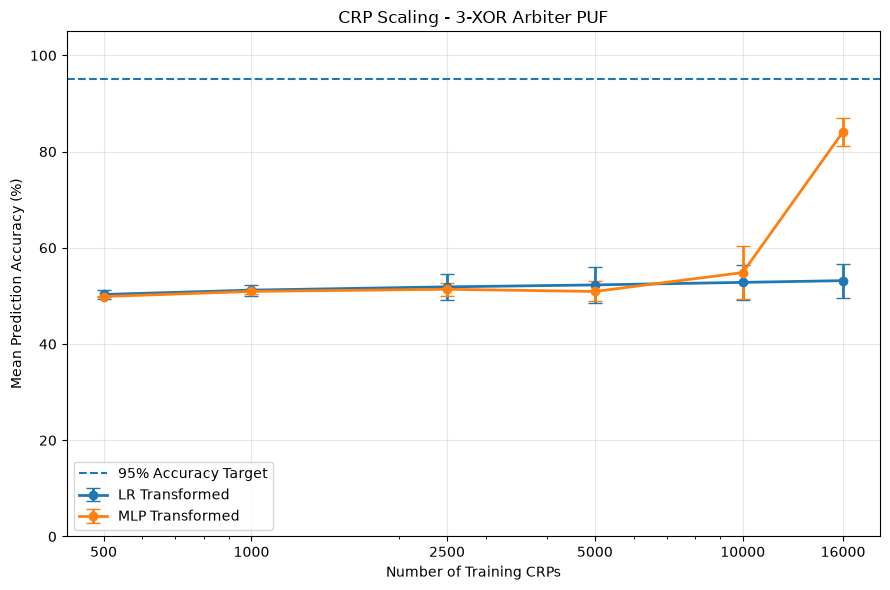

Saved: crp_scaling_3xor.png


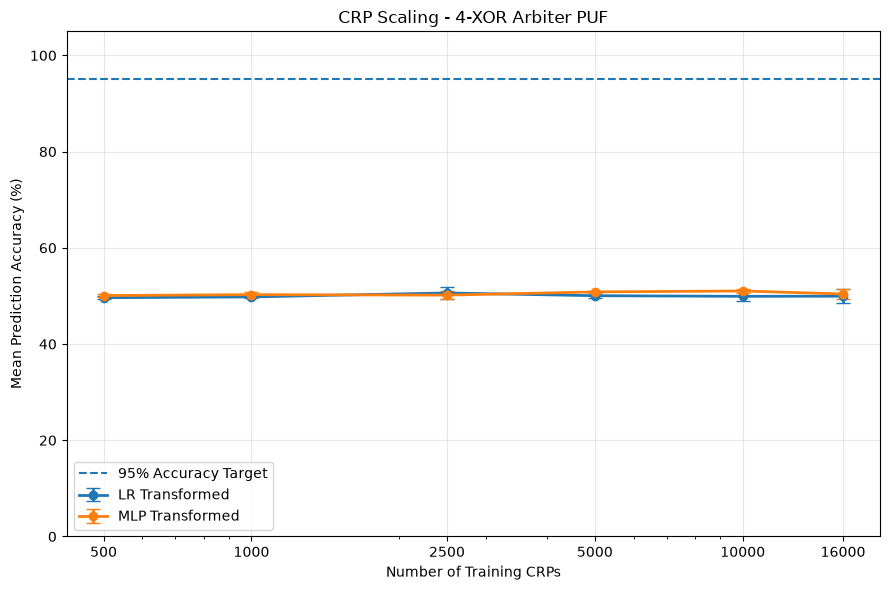

Saved: crp_scaling_4xor.png


In [6]:
for k in XOR_COUNTS:

    plt.figure(figsize=(9, 6))

    for model_name in crp_summary["Model"].unique():

        subset = crp_summary[
            (crp_summary["XOR_Count"] == k) &
            (crp_summary["Model"] == model_name)
        ].sort_values("Training_CRPs")

        plt.errorbar(
            subset["Training_CRPs"],
            subset["Mean_Accuracy"],
            yerr=subset["Std_Accuracy"],
            marker="o",
            capsize=5,
            linewidth=2,
            label=model_name
        )

    plt.axhline(
        y=95,
        linestyle="--",
        label="95% Accuracy Target"
    )

    plt.xlabel("Number of Training CRPs")
    plt.ylabel("Mean Prediction Accuracy (%)")

    plt.title(
        f"CRP Scaling - {k}-XOR Arbiter PUF"
    )

    plt.xscale("log")
    plt.xticks(
        TRAINING_SIZES,
        [str(x) for x in TRAINING_SIZES]
    )

    plt.ylim(0, 105)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    graph_file = GRAPHS_DIR / f"crp_scaling_{k}xor.png"

    plt.savefig(
        graph_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", graph_file.name)

In [7]:
threshold_results = []

for k in XOR_COUNTS:

    for model_name in crp_summary["Model"].unique():

        subset = crp_summary[
            (crp_summary["XOR_Count"] == k) &
            (crp_summary["Model"] == model_name)
        ].sort_values("Training_CRPs")

        successful = subset[
            subset["Mean_Accuracy"] >= 95
        ]

        if len(successful) > 0:
            required_crps = int(
                successful.iloc[0]["Training_CRPs"]
            )
            status = "Reached 95%"
        else:
            required_crps = None
            status = "Not reached"

        threshold_results.append({
            "XOR_Count": k,
            "Model": model_name,
            "CRPs_Required": required_crps,
            "Status": status
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

threshold_df.to_csv(
    RESULTS_DIR / "crp_95_percent_threshold.csv",
    index=False
)

,XOR_Count,Model,CRPs_Required,Status
0,1,LR Transformed,1000.0,Reached 95%
1,1,MLP Transformed,5000.0,Reached 95%
2,2,LR Transformed,NaN,Not reached
3,2,MLP Transformed,16000.0,Reached 95%
4,3,LR Transformed,NaN,Not reached
5,3,MLP Transformed,NaN,Not reached
6,4,LR Transformed,NaN,Not reached
7,4,MLP Transformed,NaN,Not reached


In [8]:
# Inspect individual seed results at the largest training size

largest_crp_results = crp_results_df[
    crp_results_df["Training_CRPs"] == 16000
].sort_values(["XOR_Count", "Model", "PUF_Seed"])

display(largest_crp_results)

,PUF_Seed,XOR_Count,Training_CRPs,Model,Accuracy,Training_Time
10,101,1,16000,LR Transformed,99.550,0.005088
58,202,1,16000,LR Transformed,99.575,0.005038
106,303,1,16000,LR Transformed,99.350,0.005852
11,101,1,16000,MLP Transformed,97.375,1.522266
59,202,1,16000,MLP Transformed,96.800,0.515698
107,303,1,16000,MLP Transformed,97.600,0.953304
22,101,2,16000,LR Transformed,49.175,0.002070
70,202,2,16000,LR Transformed,53.350,0.001867
118,303,2,16000,LR Transformed,49.500,0.002031
23,101,2,16000,MLP Transformed,95.850,0.851141
